# 02 · Modelling, Evaluation and Interpretation

This notebook **reads the outputs of `python scripts/train.py`**: the saved model and the CSV/JSON reports. Training is not repeated
here, so the numbers match the training log exactly. Run `python scripts/train.py` first.

What `scripts/train.py` does:
1. Stratified 80/20 train/test split (`random_state=42`).
2. Imbalance experiment: each untuned model × {none, class_weight, SMOTE}, 5-fold CV on train.
3. `RandomizedSearchCV` (25 iterations, 5-fold, ROC-AUC) per model.
4. Decision threshold = the F1-maximising threshold on **out-of-fold** train predictions.
5. Model selection by CV ROC-AUC. The test set is used for reporting only.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.base import clone

from src import data
from src.features import add_features
from src.preprocessing import select_features
from src.evaluation import (compute_metrics, threshold_table, plot_confusion_matrix, PALETTE, MUTED, set_style)

set_style()
pd.set_option("display.width", 140, "display.precision", 4)
REP, FIG = ROOT / "reports", ROOT / "reports" / "figures"
summary = json.loads((REP / "metrics.json").read_text())
art = joblib.load(ROOT / "models" / "best_model.joblib")
pipe, thr = art["pipeline"], art["threshold"]
print("best model:", art["model_name"], "| threshold:", round(thr, 4))
print("best params:", summary["best_params"])

best model: xgboost | threshold: 0.3515
best params: {'colsample_bytree': 0.6616014660103776, 'learning_rate': 0.047311003556264795, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 212, 'reg_lambda': 0.1348293665742147, 'subsample': 0.7015661655737379}


In [2]:
# Reproduce the identical split used in scripts/train.py
df = add_features(data.load_clean(data.find_csv(ROOT / "data" / "raw")))
X, y = select_features(df), df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
proba = pipe.predict_proba(X_test)[:, 1]
print("train", X_train.shape, "test", X_test.shape, "test churn rate %.3f" % y_test.mean())
assert np.isclose(compute_metrics(y_test, proba, 0.5)["ROC-AUC"], summary["test_metrics_threshold_0.5"]["ROC-AUC"])

train (5634, 23) test (1409, 23) test churn rate 0.265


## 1. Class imbalance

Churn rate is 26.5% (≈ 2.8 negatives per positive). The table shows untuned models in 5-fold CV on the training set at the
default 0.5 threshold.

In [3]:
imb = pd.read_csv(REP / "imbalance_cv.csv").drop(columns="key")
imb.pivot(index="model", columns="strategy", values=["roc_auc", "recall", "precision", "f1"]).round(3)

roc_auc                     recall                  precision                         f1              
strategy            class_weight   none  smote class_weight   none  smote class_weight   none  smote class_weight   none  smote
model                                                                                                                          
Decision Tree              0.659  0.654  0.661        0.493  0.502  0.518        0.502  0.483  0.486        0.497  0.492  0.502
Gradient Boosting            NaN  0.848  0.845          NaN  0.532  0.658          NaN  0.661  0.597          NaN  0.589  0.626
Logistic Regression        0.846  0.846  0.844        0.796  0.534  0.787        0.519  0.665  0.525        0.628  0.592  0.629
Random Forest              0.828  0.827  0.824        0.654  0.482  0.570        0.570  0.647  0.595        0.609  0.552  0.582
XGBoost                    0.843  0.845  0.842        0.775  0.520  0.614        0.535  0.660  0.608        0.633  0.582  0.611

**Reading this table:**

* With no re-weighting, every model catches only about **half** of the churners at threshold 0.5 (recall ≈ 0.48–0.53). The
  imbalance clearly affects how the default decision rule behaves.
* Class weights and SMOTE raise recall substantially (logistic regression 0.53 → 0.80, XGBoost 0.52 → 0.78), and precision
  falls in exchange.
* **ROC-AUC barely moves** (changes of ≤ 0.005 for every model except the untuned decision tree). Re-weighting and resampling mostly shift
  the model's **operating point**. They do not improve its ability to rank customers.
* So the simpler fix is to keep the unweighted model and **adjust the threshold**. `scripts/train.py` keeps the plain model unless a
  strategy improves CV ROC-AUC by more than 0.005. Only the untuned decision tree passed that bar (SMOTE, +0.007).

SMOTE is applied inside an `imblearn` Pipeline, so synthetic samples are generated from the training folds only. Validation
and test rows are never resampled. `tests/test_models_evaluation.py` checks this.

## 2. Tuned models: cross-validation on train

In [4]:
cv = pd.read_csv(REP / "cv_results.csv")
cv[["model", "imbalance_strategy", "cv_roc_auc", "cv_roc_auc_std", "oof_f1_threshold", "search_seconds"]]

,model,imbalance_strategy,cv_roc_auc,cv_roc_auc_std,oof_f1_threshold,search_seconds
0,Logistic Regression,none,0.8461,0.0115,0.3628,1.5
1,Decision Tree,smote,0.8197,0.0068,0.4851,2.0
2,Random Forest,none,0.8479,0.0104,0.3326,17.0
3,Gradient Boosting,none,0.8502,0.0110,0.3198,29.4
4,XGBoost,none,0.8508,0.0114,0.3515,5.4


In [5]:
for _, r in cv.iterrows():
    print(f"{r['model']:<20} {r['best_params']}")

Logistic Regression  {'C': 0.4205156450913872}
Decision Tree        {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 7}
Random Forest        {'n_estimators': 300, 'min_samples_leaf': 8, 'max_features': 0.3, 'max_depth': 6}
Gradient Boosting    {'learning_rate': 0.03203913722293047, 'max_depth': 3, 'min_samples_leaf': 30, 'n_estimators': 152, 'subsample': 0.85}
XGBoost              {'colsample_bytree': 0.6616014660103776, 'learning_rate': 0.047311003556264795, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 212, 'reg_lambda': 0.1348293665742147, 'subsample': 0.7015661655737379}


The four strong models (LogReg, RF, GB, XGBoost) sit within **0.005 ROC-AUC** of each other, while the fold-to-fold standard
deviation is ≈ 0.011. **The ranking among them is not statistically meaningful.** XGBoost is chosen because it has the highest
mean CV ROC-AUC, but logistic regression performs essentially as well and is easier to explain. For a team that values
transparency, it would be a reasonable choice.

## 3. Test-set comparison

In [6]:
t05 = pd.read_csv(REP / "test_metrics_threshold_0.5.csv", index_col=0)
print("Threshold 0.5"); display(t05.round(4))
tt = pd.read_csv(REP / "test_metrics_tuned_threshold.csv", index_col=0)
print("F1-optimal threshold (chosen on out-of-fold train predictions)"); display(tt.round(4))

Threshold 0.5


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.7999,0.6554,0.5187,0.5791,0.8421
Decision Tree,0.7771,0.5765,0.6043,0.5901,0.8117
Random Forest,0.7991,0.6667,0.4866,0.5626,0.8445
Gradient Boosting,0.8020,0.6632,0.5160,0.5805,0.8465
XGBoost,0.7991,0.6585,0.5053,0.5719,0.8476


F1-optimal threshold (chosen on out-of-fold train predictions)


,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Logistic Regression,0.3628,0.7757,0.5622,0.7005,0.6238,0.8421
Decision Tree,0.4851,0.7580,0.5361,0.6551,0.5897,0.8117
Random Forest,0.3326,0.7736,0.5542,0.7513,0.6379,0.8445
Gradient Boosting,0.3198,0.7757,0.5585,0.7406,0.6368,0.8465
XGBoost,0.3515,0.7807,0.5681,0.7246,0.6369,0.8476


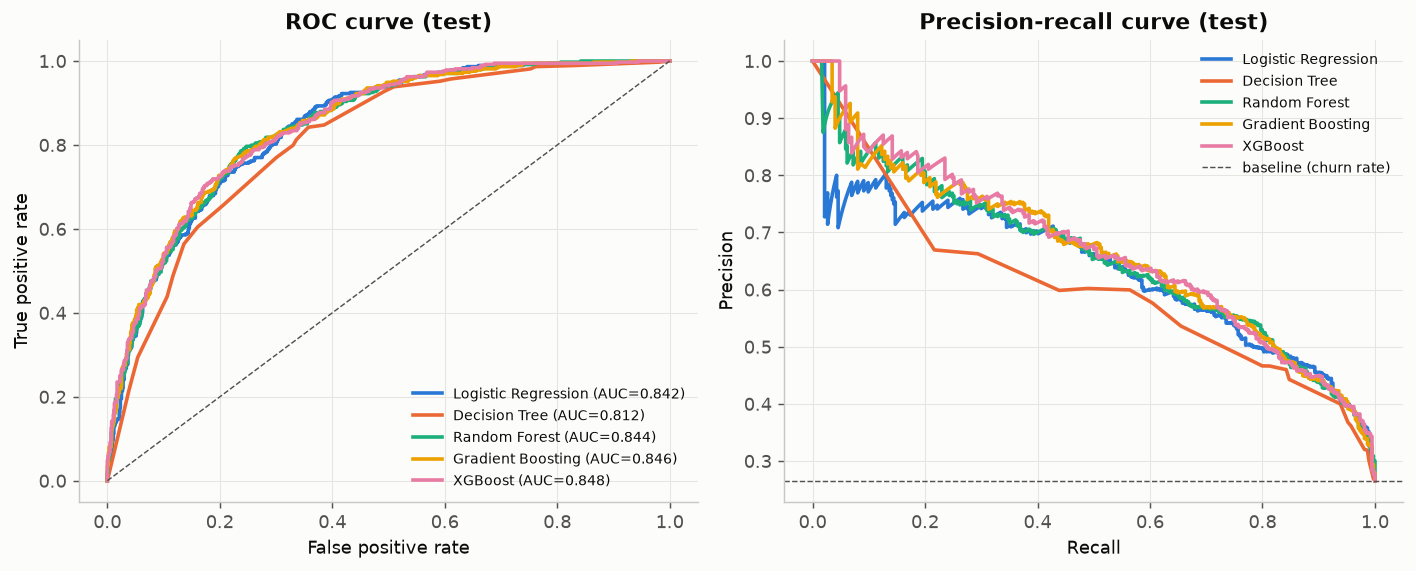

In [7]:
display(Image(FIG / 'roc_pr_curves.png'))

* **Accuracy is about 80%** for every model except the decision tree. The required 85% is **not reached** by any model in this
  setup. The results are reported as measured. For context, "predict no churn for everyone" scores 73.5%.
* Best test ROC-AUC is 0.848 (XGBoost). The decision tree trails at 0.812.
* At the tuned threshold, recall rises from ≈ 0.50 to ≈ 0.70–0.75 for all strong models. Precision drops from ≈ 0.66 to ≈ 0.56
  and accuracy falls by about 2 points, while F1 improves from ≈ 0.57 to ≈ 0.64.

## 4. Precision / recall trade-off for the selected model

In [8]:
tbl = threshold_table(y_test, proba)
tbl[["Precision", "Recall", "F1", "Accuracy", "flagged_pct"]].round(3)

,Precision,Recall,F1,Accuracy,flagged_pct
threshold,,,,,
0.10,0.405,0.941,0.566,0.617,0.617
0.15,0.448,0.901,0.599,0.679,0.534
0.20,0.472,0.842,0.605,0.708,0.473
0.25,0.499,0.810,0.618,0.734,0.431
0.30,0.528,0.773,0.628,0.757,0.388
0.35,0.567,0.725,0.636,0.780,0.339
0.40,0.605,0.671,0.636,0.796,0.295
0.45,0.637,0.602,0.619,0.803,0.251
0.50,0.659,0.505,0.572,0.799,0.204


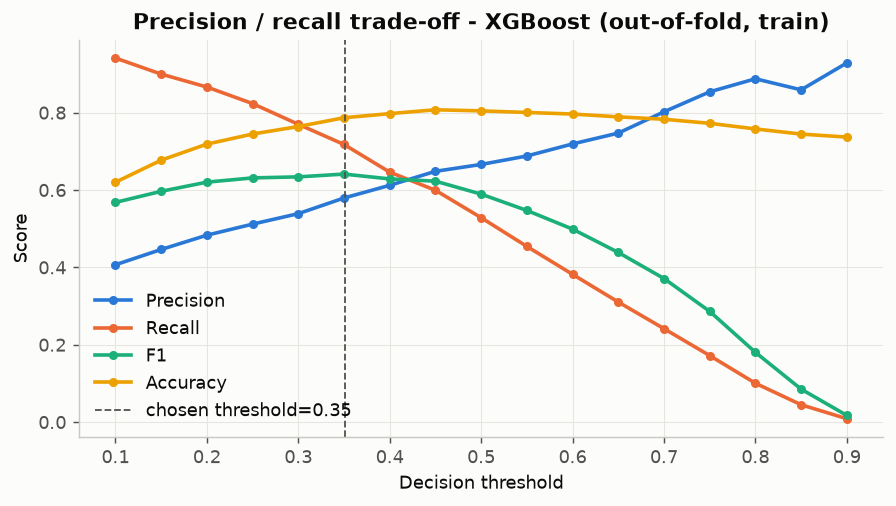

In [9]:
display(Image(FIG / 'threshold_tradeoff_oof.png'))

The plot uses out-of-fold **training** predictions, which is the data the threshold was chosen on. The table above shows the
same sweep on the test set for reference only. The test set was not used to pick the threshold.

**Which threshold?** That is a business decision, not a modelling one:

* If a retention offer is **cheap** (an email, a small discount) and losing a customer is expensive, a **lower** threshold makes
  sense. At 0.30 the model flags about 39% of customers and catches about 77% of churners.
* If the intervention is **expensive** (a call-centre agent, a large discount), a **higher** threshold keeps precision up.
  At 0.5, about two in three flagged customers really churn, but half of the churners are missed.
* The F1-optimal threshold (≈ 0.35) is a neutral default. With a real cost matrix (offer cost, customer lifetime value,
  offer acceptance rate), the threshold should instead be chosen to minimise expected cost.

## 5. Confusion matrices (selected model, test set)

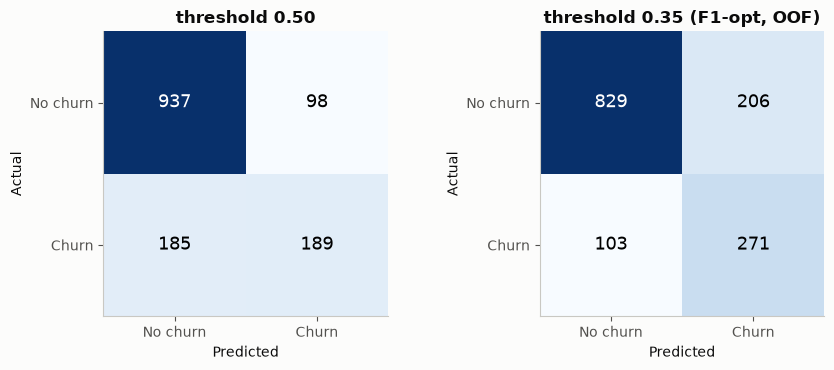

[[TN, FP], [FN, TP]] @0.5: [[937, 98], [185, 189]]
[[TN, FP], [FN, TP]] @thr: [[829, 206], [103, 271]]


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (t, label) in zip(axes, [(0.5, "threshold 0.50"), (thr, f"threshold {thr:.2f} (F1-opt, OOF)")]):
    from sklearn.metrics import confusion_matrix
    cm = confusion_matrix(y_test, (proba >= t).astype(int))
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["No churn", "Churn"]); ax.set_yticks([0, 1], ["No churn", "Churn"])
    ax.set(xlabel="Predicted", ylabel="Actual", title=label)
fig.tight_layout(); plt.show()
print("[[TN, FP], [FN, TP]] @0.5:", summary["confusion_matrix_threshold_0.5"])
print("[[TN, FP], [FN, TP]] @thr:", summary["confusion_matrix_tuned_threshold"])

Lowering the threshold from 0.50 to 0.35 catches **82 more churners** (TP 189 → 271, FN 185 → 103). The cost is **108 more
false alarms** (FP 98 → 206).

## 6. Feature importance

Three complementary views:
1. **Permutation importance** on the test set, computed per *raw* column so one-hot groups are shuffled together. It is
   model-agnostic and measures the drop in ROC-AUC.
2. **Built-in tree importance** (XGBoost gain-based) and **logistic-regression coefficients** on the encoded features.
3. **SHAP** (TreeExplainer) for direction and per-customer attribution.

,importance_mean,importance_std
Contract,0.0547,0.0054
tenure,0.0424,0.0025
InternetService,0.0082,0.0039
TotalCharges,0.0066,0.0017
OnlineSecurity,0.0058,0.0012
TechSupport,0.0044,0.0015
PaymentMethod,0.0033,0.0012
PaperlessBilling,0.0022,0.0012
MultipleLines,0.0021,0.0010
MonthlyCharges,0.0021,0.0021


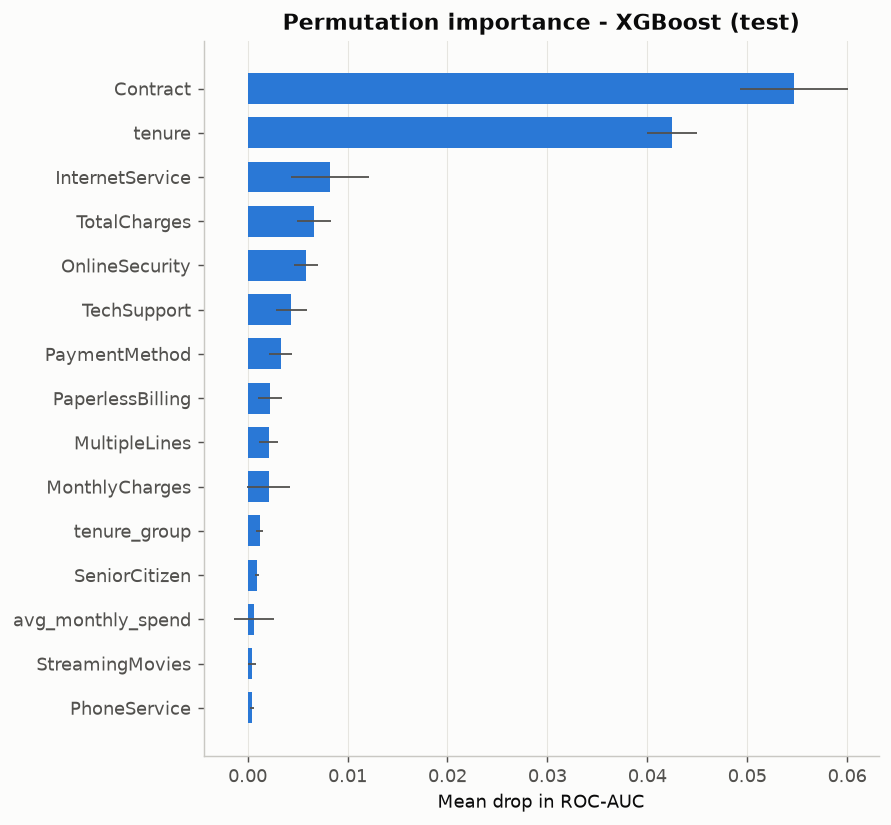

In [11]:
perm = pd.read_csv(REP / "permutation_importance.csv", index_col=0)
display(perm.round(4))
display(Image(FIG / "permutation_importance.png"))

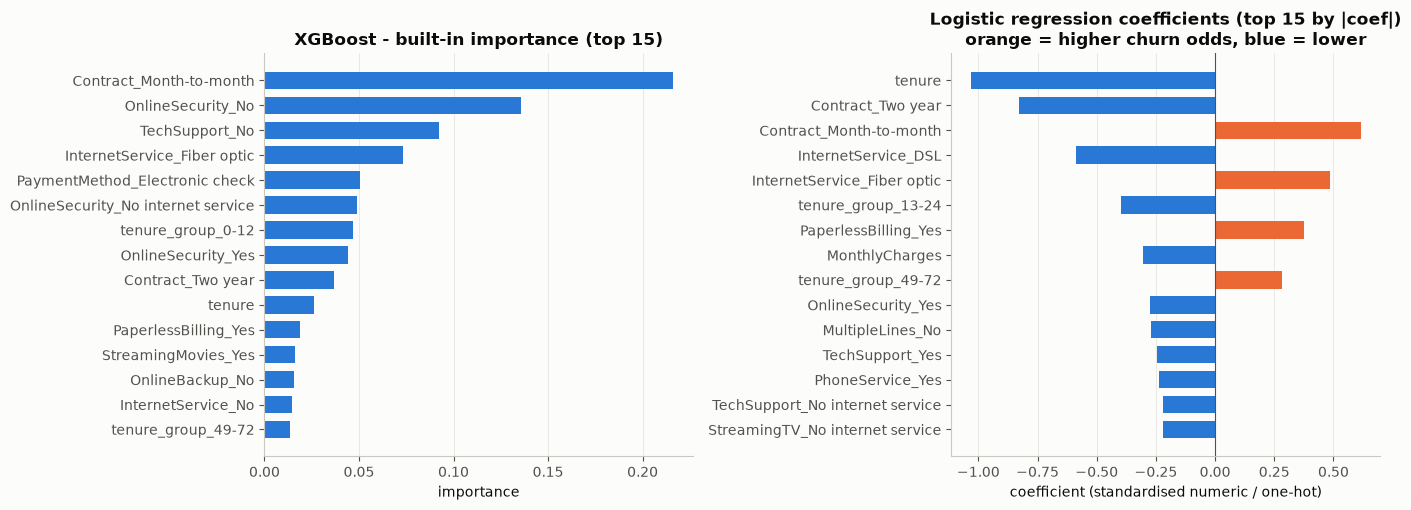

In [12]:
xgb_imp = pd.read_csv(REP / "model_importance_xgboost.csv", index_col=0)["importance"]
lr_coef = pd.read_csv(REP / "model_importance_logistic_regression.csv", index_col=0)["importance"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
s = xgb_imp.head(15)[::-1]
axes[0].barh(s.index, s.values, color=PALETTE[0], height=0.7); axes[0].grid(axis="y", visible=False)
axes[0].set(title="XGBoost - built-in importance (top 15)", xlabel="importance")
c = lr_coef.head(15)[::-1]
axes[1].barh(c.index, c.values, color=[PALETTE[1] if v > 0 else PALETTE[0] for v in c.values], height=0.7)
axes[1].axvline(0, color=MUTED, lw=0.8); axes[1].grid(axis="y", visible=False)
axes[1].set(title="Logistic regression coefficients (top 15 by |coef|)\norange = higher churn odds, blue = lower",
            xlabel="coefficient (standardised numeric / one-hot)")
fig.tight_layout(); fig.savefig(FIG / "xgb_importance_vs_logreg_coef.png", dpi=130, bbox_inches="tight"); plt.show()

LogReg coefficients are conditional on all other features and are affected by collinearity. For example, `tenure`,
`tenure_group`, `TotalCharges` and `MonthlyCharges` share information, so individual signs, such as the negative
`MonthlyCharges` coefficient, should not be read in isolation.

<site-packages>\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


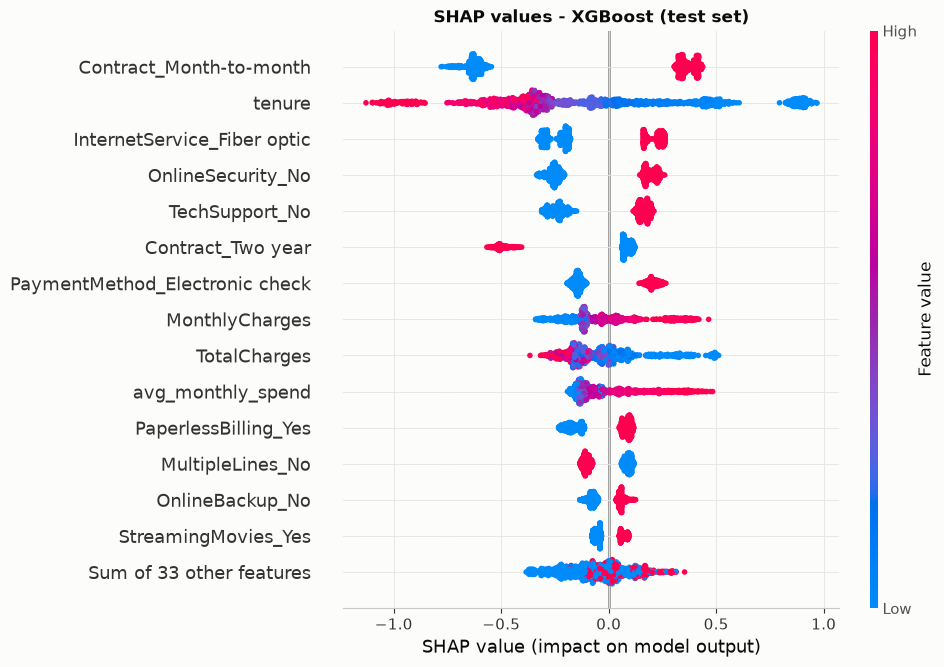

,mean |SHAP| (log-odds)
Contract_Month-to-month,0.4843
tenure,0.4226
InternetService_Fiber optic,0.2346
OnlineSecurity_No,0.2259
TechSupport_No,0.1989
Contract_Two year,0.1848
PaymentMethod_Electronic check,0.1668
MonthlyCharges,0.1472
TotalCharges,0.1323
avg_monthly_spend,0.1290


In [13]:
try:
    import shap
    pre, clf = pipe.named_steps["pre"], pipe.named_steps["clf"]
    Xt = pd.DataFrame(pre.transform(X_test), columns=pre.get_feature_names_out(), index=X_test.index)
    explainer = shap.TreeExplainer(clf)
    sv = explainer(Xt)
    plt.figure()
    shap.plots.beeswarm(sv, max_display=15, show=False)
    plt.title("SHAP values - XGBoost (test set)")
    plt.gcf().savefig(FIG / "shap_beeswarm.png", dpi=130, bbox_inches="tight"); plt.show()
    mean_abs = pd.Series(np.abs(sv.values).mean(0), index=Xt.columns).sort_values(ascending=False)
    display(mean_abs.head(12).round(4).to_frame("mean |SHAP| (log-odds)"))
except ImportError:
    print("shap not installed - skipping (pip install shap)")

### Most important churn predictors (consistent across all three methods)

1. **Contract type.** Month-to-month contracts are associated with much higher churn risk, and two-year contracts with very
   low risk. This is the top permutation feature (−0.055 AUC when shuffled).
2. **Tenure.** New customers are at the highest risk (−0.042 AUC when shuffled).
3. **Internet service = Fibre optic.** It is associated with higher risk, partly through its higher price.
4. **No OnlineSecurity / no TechSupport.** Both are associated with higher risk.
5. **Payment by electronic check** and **paperless billing** are associated with higher risk.
6. **TotalCharges / MonthlyCharges** carry smaller additional signal.

`gender`, `Partner`, `StreamingTV` and the engineered counts contribute essentially nothing once the features above are known.

SHAP and permutation importance disagree on `avg_monthly_spend`. SHAP gives it a sizeable share (mean |SHAP| ≈ 0.13), while
shuffling it costs almost no ROC-AUC (0.0006 ± 0.002). The reason is that it is ≈ 0.996 correlated with `MonthlyCharges`.
The trees split on either one, so SHAP divides the credit between them, but shuffling one does little damage while the other
is still intact. Neither method is wrong. Collinear features make any single attribution unstable.

### Association is not causation

These importances describe **what the model relies on to predict churn**, not **why customers churn**. For example:
* Month-to-month contracts may not *cause* churn. Customers who already intend to leave are more likely to avoid long
  contracts (self-selection, reverse causality).
* Electronic-check payers may differ in unobserved ways, such as demographics or credit profile, that drive both the payment
  method and churn (confounding).
* Fibre customers may churn because of price, service quality or competitor offers. The data cannot tell these apart.

Estimating the effect of an intervention, such as "offer a one-year contract", would need an A/B test or a causal-inference
design, not feature importance.

## 7. Did the engineered features help? (ablation)

The tuned XGBoost configuration is re-run with 5-fold CV on train, with and without the four engineered features. Only the
training set is used.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from src.preprocessing import NUMERIC_FEATURES, CATEGORICAL_FEATURES
from src.features import ENGINEERED_FEATURES

def make_pipe(num, cat):
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False))]), cat),
    ])
    return Pipeline([("pre", pre), ("clf", clone(pipe.named_steps["clf"]))])

cv5 = StratifiedKFold(5, shuffle=True, random_state=42)
rows = {}
for label, drop in [("with engineered features", []), ("without engineered features", ENGINEERED_FEATURES)]:
    num = [c for c in NUMERIC_FEATURES if c not in drop]; cat = [c for c in CATEGORICAL_FEATURES if c not in drop]
    s = cross_val_score(make_pipe(num, cat), X_train, y_train, cv=cv5, scoring="roc_auc", n_jobs=-1)
    rows[label] = {"cv_roc_auc_mean": s.mean(), "cv_roc_auc_std": s.std()}
pd.DataFrame(rows).T.round(4)

,cv_roc_auc_mean,cv_roc_auc_std
with engineered features,0.8508,0.0114
without engineered features,0.8510,0.0117


The difference is well within one standard deviation, so **the engineered features neither help nor hurt** the boosted model
in any measurable way. This is not surprising: `tenure_group` is a coarsening of `tenure`, `avg_monthly_spend` is ≈ 0.996
correlated with `MonthlyCharges`, and the service counts are sums of columns the model already sees. They are kept because
they are cheap, well-defined and readable for business users ("customers in their first year", "number of services"). They
were **not** added or kept to inflate the score.

## 8. Summary

| | value |
|---|---|
| Selected model | XGBoost (max_depth 2, 212 trees, learning rate ≈ 0.047) |
| CV ROC-AUC (train, 5-fold) | 0.851 ± 0.011 |
| Test ROC-AUC | 0.848 |
| Test accuracy @0.5 | 0.799 |
| Test precision / recall / F1 @0.5 | 0.659 / 0.505 / 0.572 |
| Test precision / recall / F1 @0.35 | 0.568 / 0.725 / 0.637 |

**Limitations:** this is a single static snapshot of one fictional telco with no timestamps, so there is no temporal
validation and no information about when customers churned. The test set is small (374 churners), so metric differences below
about 0.01 are noise. The probabilities have not been calibrated for cost-based decisions.